In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [3]:
# Load the CSV file
df = pd.read_csv("housing.csv")

In [4]:
# Display the first 5 rows
display(df.head())

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [5]:
# Check the dataset dimensions
print("Dataset shape:", df.shape)

Dataset shape: (20640, 10)


In [9]:
# Check column names, data types, and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


In [10]:
# Count missing values in each column
print(df.isnull().sum())

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64


In [11]:
display(df.head())

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [12]:
# Calculate the median number of bedrooms
median_bedrooms = df["total_bedrooms"].median()

print("Median total bedrooms:", median_bedrooms)

Median total bedrooms: 435.0


In [13]:
# Replace missing values with the median
df["total_bedrooms"] = df["total_bedrooms"].fillna(median_bedrooms)

# Verify that missing values have been handled
print("Missing total_bedrooms:", df["total_bedrooms"].isnull().sum())

Missing total_bedrooms: 0


In [14]:
print("Total missing values:", df.isnull().sum().sum())
print("Dataset shape:", df.shape)

Total missing values: 0
Dataset shape: (20640, 10)


In [15]:
# Summary statistics for numerical columns
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
longitude,20640.0,-119.569704,2.003532,-124.3500,-121.8000,-118.4900,-118.01000,-114.3100
latitude,20640.0,35.631861,2.135952,32.5400,33.9300,34.2600,37.71000,41.9500
housing_median_age,20640.0,28.639486,12.585558,1.0000,18.0000,29.0000,37.00000,52.0000
total_rooms,20640.0,2635.763081,2181.615252,2.0000,1447.7500,2127.0000,3148.00000,39320.0000
total_bedrooms,20640.0,536.838857,419.391878,1.0000,297.0000,435.0000,643.25000,6445.0000
population,20640.0,1425.476744,1132.462122,3.0000,787.0000,1166.0000,1725.00000,35682.0000
households,20640.0,499.539680,382.329753,1.0000,280.0000,409.0000,605.00000,6082.0000
median_income,20640.0,3.870671,1.899822,0.4999,2.5634,3.5348,4.74325,15.0001
median_house_value,20640.0,206855.816909,115395.615874,14999.0000,119600.0000,179700.0000,264725.00000,500001.0000


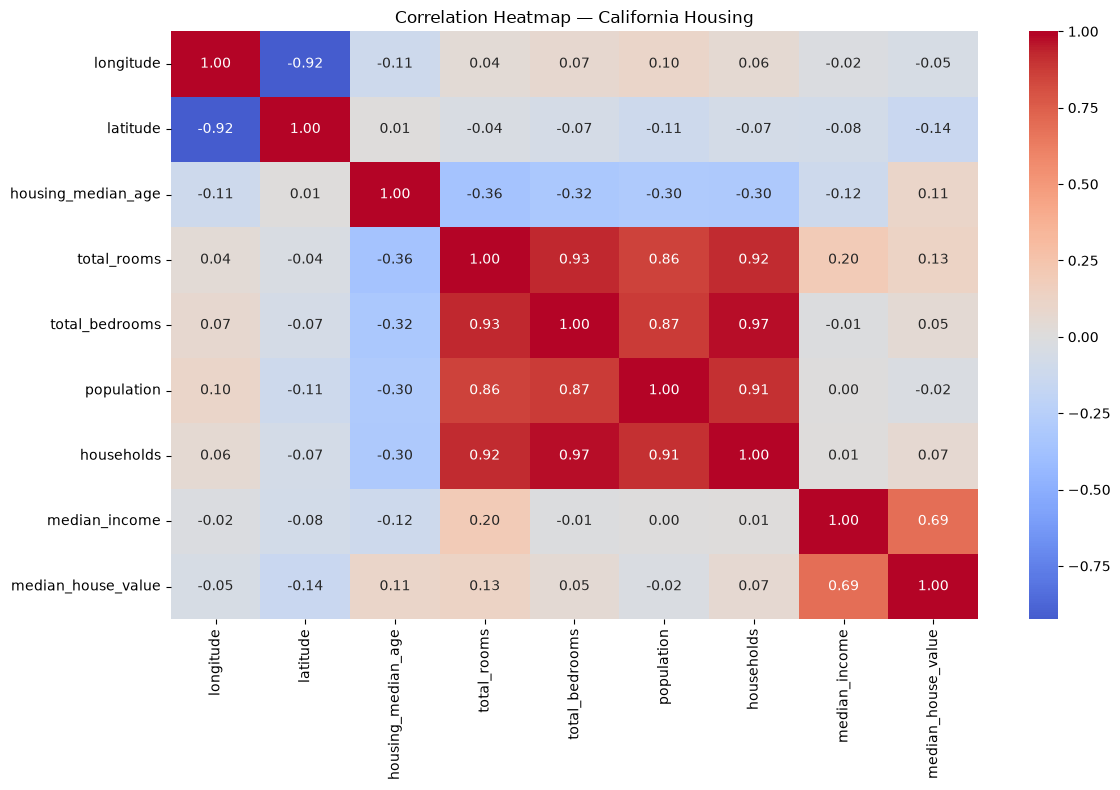

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical columns
numeric_df = df.select_dtypes(include="number")

# Calculate correlations
correlation_matrix = numeric_df.corr()

# Plot heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Heatmap — California Housing")
plt.tight_layout()
plt.show()

In [17]:
# Features: everything except the value we want to predict
X = df.drop("median_house_value", axis=1)

# Target: the value we want to predict
y = df["median_house_value"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("Target variable:", y.name)

Features shape: (20640, 9)
Target shape: (20640,)
Target variable: median_house_value


In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

Training features: (16512, 9)
Testing features: (4128, 9)
Training targets: (16512,)
Testing targets: (4128,)


In [19]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.pipeline import Pipeline

numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("interactions", PolynomialFeatures(
        degree=2,
        interaction_only=True,
        include_bias=False
    )),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# Fit preprocessing on training data only
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same transformations to the test data
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (16512, 41)
Processed testing shape: (4128, 41)


In [20]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import Pipeline

models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso Regression": Lasso(alpha=100.0, max_iter=10000)
}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)
    print(f"{name}: trained successfully")

Linear Regression: trained successfully
Ridge Regression: trained successfully
Lasso Regression: trained successfully


In [21]:

from sklearn.model_selection import cross_validate
from sklearn.base import clone
import numpy as np

results = []

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", clone(model))
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=5,
        scoring={
            "rmse": "neg_root_mean_squared_error",
            "r2": "r2"
        },
        n_jobs=-1
    )

    results.append({
        "Model": name,
        "Mean CV RMSE": -scores["test_rmse"].mean(),
        "Mean CV R²": scores["test_r2"].mean()
    })

import pandas as pd

results_df = pd.DataFrame(results)
print(results_df.round(3).to_string(index=False))


            Model  Mean CV RMSE  Mean CV R²
Linear Regression     64621.885       0.687
 Ridge Regression     65505.692       0.679
 Lasso Regression     65980.326       0.674


In [22]:

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.base import clone
import pandas as pd
import numpy as np

test_results = []
fitted_models = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", clone(model))
    ])

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    test_results.append({
        "Model": name,
        "Test RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "Test MAE": mean_absolute_error(y_test, predictions),
        "Test R²": r2_score(y_test, predictions)
    })

    fitted_models[name] = pipeline

test_results_df = pd.DataFrame(test_results)
print(test_results_df.round(3).to_string(index=False))


            Model  Test RMSE  Test MAE  Test R²
Linear Regression  66789.431 47282.634    0.660
 Ridge Regression  67772.272 48194.772    0.649
 Lasso Regression  68252.098 48709.984    0.645


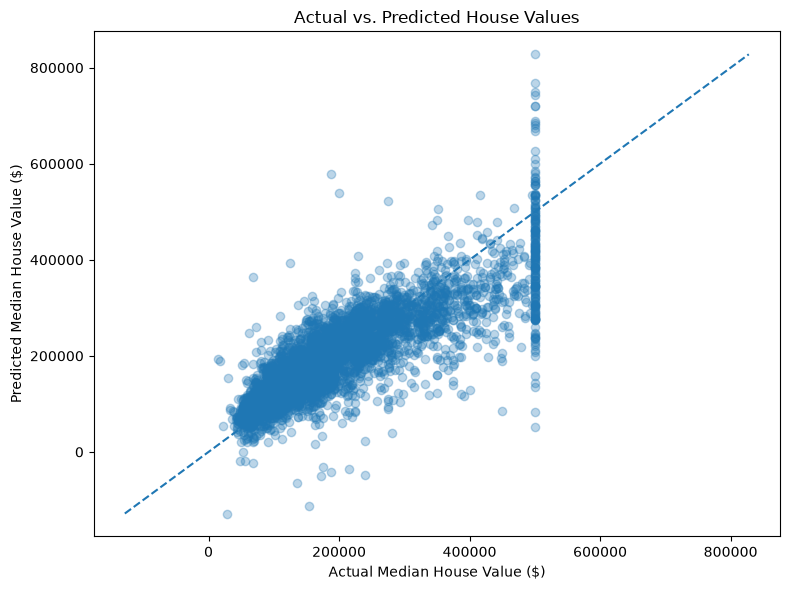

In [23]:

import matplotlib.pyplot as plt

best_model = fitted_models["Linear Regression"]
y_pred = best_model.predict(X_test)

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.3)

# Ideal predictions fall on this diagonal line
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())
plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Median House Value ($)")
plt.ylabel("Predicted Median House Value ($)")
plt.title("Actual vs. Predicted House Values")
plt.tight_layout()
plt.show()


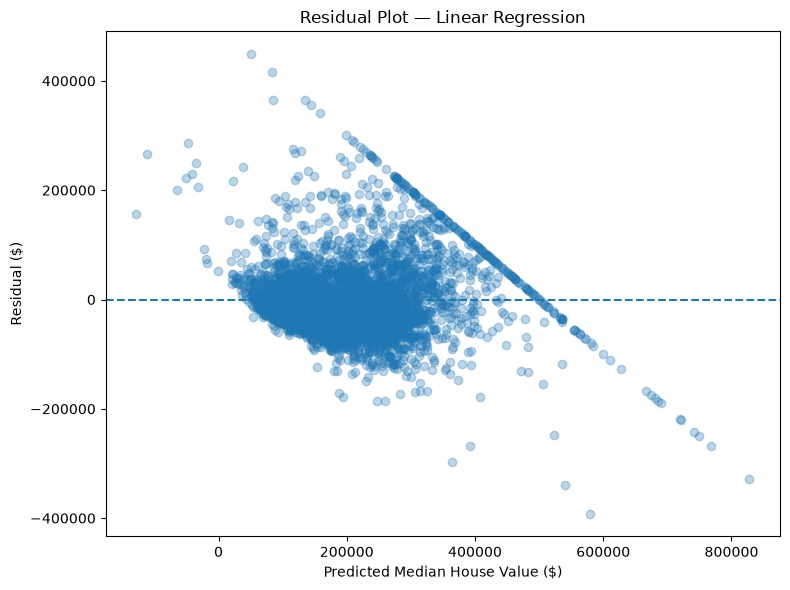

In [24]:

import matplotlib.pyplot as plt

best_model = fitted_models["Linear Regression"]
y_pred = best_model.predict(X_test)

residuals = y_test - y_pred

plt.figure(figsize=(8, 6))
plt.scatter(y_pred, residuals, alpha=0.3)
plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Median House Value ($)")
plt.ylabel("Residual ($)")
plt.title("Residual Plot — Linear Regression")
plt.tight_layout()
plt.show()


## Conclusion

In this project, I developed a machine learning regression workflow to predict median house values using the California Housing dataset. I began by inspecting and cleaning the data, including imputing missing values in the `total_bedrooms` column. I then explored the dataset and created a preprocessing pipeline that included numerical scaling, categorical encoding, and pairwise interaction features.

I trained and compared three models: Linear Regression, Ridge Regression, and Lasso Regression. Linear Regression achieved the best performance, with a cross-validation RMSE of approximately $64,622 and a mean cross-validation R² of 0.687. On the held-out test set, it achieved an RMSE of $66,789.43, an MAE of $47,282.63, and an R² of 0.660.

Finally, I used actual-versus-predicted and residual plots to examine the model's predictions and errors. Overall, the results show that Linear Regression provides a useful baseline, although prediction errors remain substantial. Future improvements could include testing nonlinear models, tuning regularization parameters, and investigating the effects of the dataset's capped house values.
